# Optimizer Tuning

Compares three optimizer configurations training **Model A** on the real RealWaste train/val split, for 20 epochs each:

1. Standard SGD (momentum = 0.0)
2. SGD with Momentum (momentum = 0.9)
3. Adam

Every run starts from the **same** initial weights (re-seeded before each model is built) so differences in the curves come only from the optimizer, not from a lucky/unlucky initialization.

A second experiment then sweeps Adam's learning rate (`1e-2`, `1e-3`, `1e-4`) to justify the learning rate used for the rest of the assignment. All choices are made on the **validation** set; the test set is never used here.

In [1]:
import matplotlib.pyplot as plt
import torch

from data_loader import get_dataloaders, set_seed
from models import ModelA
from train_utils import train_model

EPOCHS = 20
train_loader, val_loader, test_loader = get_dataloaders(batch_size=32)

In [2]:
configs = {
    "SGD (momentum=0.0)": lambda params: torch.optim.SGD(params, lr=0.01, momentum=0.0),
    "SGD (momentum=0.9)": lambda params: torch.optim.SGD(params, lr=0.01, momentum=0.9),
    "Adam": lambda params: torch.optim.Adam(params, lr=0.001),
}

results = {}
for name, make_optimizer in configs.items():
    print(f"\n=== {name} ===")
    set_seed()  # same starting weights for every config
    model = ModelA()
    optimizer = make_optimizer(model.parameters())
    history, avg_epoch_time = train_model(model, train_loader, val_loader, optimizer, epochs=EPOCHS)
    results[name] = {"history": history, "avg_epoch_time": avg_epoch_time}


=== SGD (momentum=0.0) ===


epoch 1/20  train_loss 2.1651 train_acc 0.191  val_loss 2.1442 val_acc 0.194


epoch 2/20  train_loss 2.1415 train_acc 0.194  val_loss 2.1376 val_acc 0.192


epoch 3/20  train_loss 2.1351 train_acc 0.199  val_loss 2.1304 val_acc 0.194


epoch 4/20  train_loss 2.1254 train_acc 0.202  val_loss 2.1169 val_acc 0.191


...

epoch 16/20  train_loss 0.5793 train_acc 0.807  val_loss 1.0118 val_acc 0.674


epoch 17/20  train_loss 0.5247 train_acc 0.817  val_loss 1.0283 val_acc 0.673


epoch 18/20  train_loss 0.5032 train_acc 0.826  val_loss 1.1097 val_acc 0.649


epoch 19/20  train_loss 0.4913 train_acc 0.828  val_loss 1.0855 val_acc 0.660


epoch 20/20  train_loss 0.4396 train_acc 0.837  val_loss 1.1176 val_acc 0.656


## Training vs. validation curves

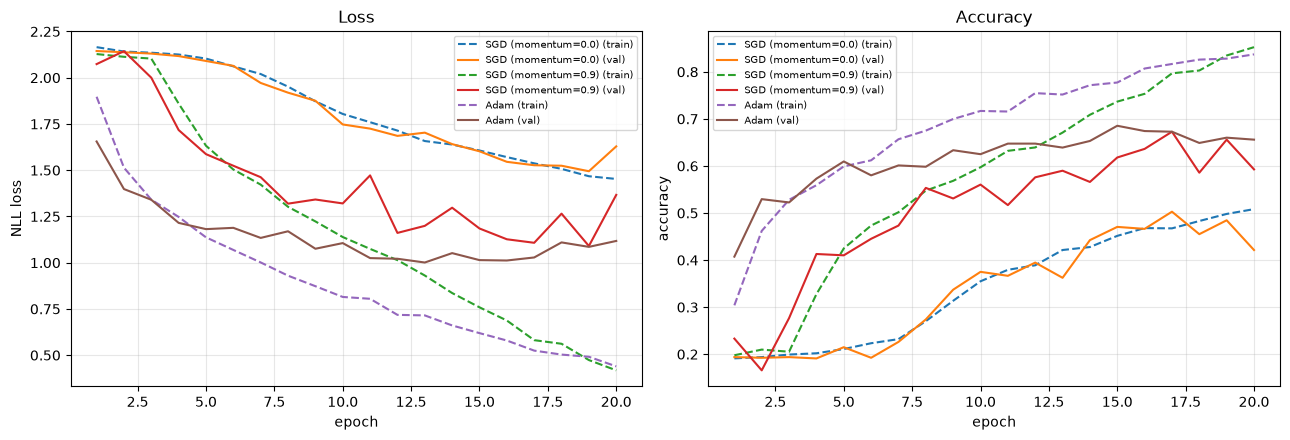

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
epochs_range = range(1, EPOCHS + 1)

for name, result in results.items():
    h = result["history"]
    axes[0].plot(epochs_range, h["train_loss"], linestyle="--", label=f"{name} (train)")
    axes[0].plot(epochs_range, h["val_loss"], linestyle="-", label=f"{name} (val)")
    axes[1].plot(epochs_range, h["train_acc"], linestyle="--", label=f"{name} (train)")
    axes[1].plot(epochs_range, h["val_acc"], linestyle="-", label=f"{name} (val)")

axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("NLL loss")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
for ax in axes:
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
print(f"{'optimizer':22s} {'final val_acc':>14s} {'best val_acc':>13s} {'s/epoch':>9s}")
for name, result in results.items():
    h = result["history"]
    print(f"{name:22s} {h['val_acc'][-1]:14.3f} {max(h['val_acc']):13.3f} {result['avg_epoch_time']:9.2f}")

optimizer               final val_acc  best val_acc   s/epoch
SGD (momentum=0.0)              0.421         0.503      3.06
SGD (momentum=0.9)              0.593         0.673      3.04
Adam                            0.656         0.685      3.07


## Learning-rate sweep for Adam

Same setup as above (Model A, identical initial weights, 20 epochs), changing only Adam's learning rate by factors of 10 around its common default. The `lr=1e-3` run is the Adam run from above, reused rather than retrained (same seed, so it would be identical).

In [5]:
sweep_lrs = [1e-2, 1e-3, 1e-4]
lr_results = {1e-3: results["Adam"]}

for lr in sweep_lrs:
    if lr in lr_results:
        continue
    print(f"\n=== Adam (lr={lr:g}) ===")
    set_seed()  # same starting weights as every other run
    model = ModelA()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history, avg_epoch_time = train_model(model, train_loader, val_loader, optimizer, epochs=EPOCHS)
    lr_results[lr] = {"history": history, "avg_epoch_time": avg_epoch_time}


=== Adam (lr=0.01) ===


epoch 1/20  train_loss 2.1581 train_acc 0.188  val_loss 2.1228 val_acc 0.216


epoch 2/20  train_loss 2.0789 train_acc 0.211  val_loss 2.0607 val_acc 0.219


epoch 3/20  train_loss 1.9884 train_acc 0.249  val_loss 1.9712 val_acc 0.249


epoch 4/20  train_loss 1.9064 train_acc 0.290  val_loss 1.8796 val_acc 0.303


...

epoch 16/20  train_loss 1.2369 train_acc 0.561  val_loss 1.2914 val_acc 0.552


epoch 17/20  train_loss 1.2163 train_acc 0.562  val_loss 1.3086 val_acc 0.539


epoch 18/20  train_loss 1.1996 train_acc 0.568  val_loss 1.3117 val_acc 0.532


epoch 19/20  train_loss 1.1920 train_acc 0.579  val_loss 1.2591 val_acc 0.555


epoch 20/20  train_loss 1.1673 train_acc 0.581  val_loss 1.2515 val_acc 0.572


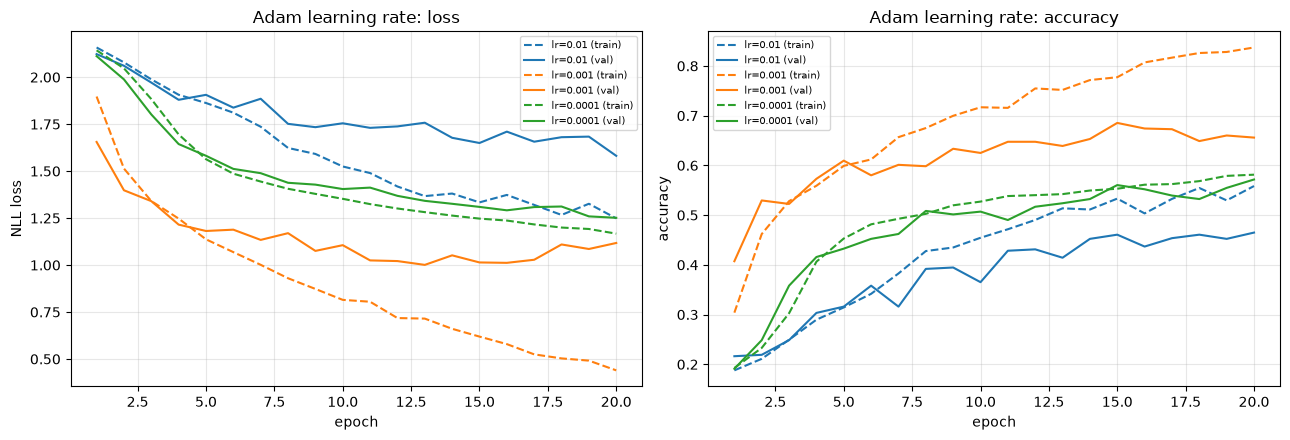

 Adam lr  final val_acc  best val_acc  lowest val_loss  at epoch
    0.01          0.465         0.465           1.5814        20
   0.001          0.656         0.685           1.0010        13
  0.0001          0.572         0.572           1.2515        20


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for lr in sweep_lrs:
    h = lr_results[lr]["history"]
    line, = axes[0].plot(epochs_range, h["train_loss"], linestyle="--", label=f"lr={lr:g} (train)")
    axes[0].plot(epochs_range, h["val_loss"], color=line.get_color(), label=f"lr={lr:g} (val)")
    axes[1].plot(epochs_range, h["train_acc"], linestyle="--", color=line.get_color(), label=f"lr={lr:g} (train)")
    axes[1].plot(epochs_range, h["val_acc"], color=line.get_color(), label=f"lr={lr:g} (val)")

axes[0].set_title("Adam learning rate: loss"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("NLL loss")
axes[1].set_title("Adam learning rate: accuracy"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
for ax in axes:
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'Adam lr':>8s} {'final val_acc':>14s} {'best val_acc':>13s} {'lowest val_loss':>16s} {'at epoch':>9s}")
for lr in sweep_lrs:
    h = lr_results[lr]["history"]
    best_epoch = min(range(EPOCHS), key=lambda e: h["val_loss"][e])
    print(f"{lr:8g} {h['val_acc'][-1]:14.3f} {max(h['val_acc']):13.3f} {h['val_loss'][best_epoch]:16.4f} {best_epoch + 1:9d}")

## Analysis

All numbers are on the validation set (Model A, 20 epochs, identical initial weights):

| Optimizer | Learning rate | Final val acc | Best val acc | Lowest val loss | s/epoch |
|---|---|---|---|---|---|
| SGD | 0.01 | 42.1% | 50.3% | 1.49 | 3.06 |
| SGD + momentum 0.9 | 0.01 | 59.3% | 67.3% | 1.09 | 3.04 |
| **Adam** | **0.001** | **65.6%** | **68.5%** | **1.00** | 3.07 |

**Effect of momentum.** Plain SGD barely moves for the first 7 epochs: validation accuracy sits at about 19.4%, exactly the share of the largest class (Plastic, 138 of 712 validation images), so the model is still predicting mostly one class. It only breaks away around epoch 8 and reaches 50.3% at best. Momentum (0.9) adds a running average of past gradients to every step, so gradient directions that stay consistent across batches build up speed (at steady state the effective step is about `lr / (1 - 0.9)` = 10x larger), while noisy batch-to-batch components partly cancel out. At the same learning rate, the model leaves the one-class plateau by epoch 3-4 instead of 8 and reaches 67.3% best validation accuracy instead of 50.3%. The downside is visible too: with that larger effective step and no learning-rate decay, it overshoots. Validation accuracy swings by up to 9 points between consecutive epochs (67.3% -> 58.6% -> 65.6% -> 59.3% over the last four), so its final-epoch accuracy is 8 points below its best, and the result depends heavily on when training happens to stop.

**Why Adam.** Adam reaches the highest best validation accuracy (68.5%) and the lowest validation loss (1.00) of the three, and its validation curve is far steadier than SGD with momentum's (final 65.6% vs best 68.5%). Adam keeps per-parameter running estimates of the gradient's mean (like momentum) and of its squared magnitude, and divides each step by the latter, so every parameter gets a step size suited to its own gradient scale instead of one global learning rate. It costs nothing extra where it matters for an edge device: time per epoch is the same (~3.1 s), the two extra values it stores per parameter exist only during training (3 x 60k floats, under 1 MB), and the deployed model is identical.

**Why lr = 0.001: the learning-rate sweep.** Adam is *not* insensitive to its learning rate, so the value is chosen from the sweep above rather than by default:

| Adam lr | Best val acc | Lowest val loss (epoch) | Behaviour |
|---|---|---|---|
| 0.01 | 46.5% | 1.58 (20) | Too large: updates overshoot, validation loss is erratic and training accuracy only reaches 56% |
| **0.001** | **68.5%** | **1.00 (13)** | Fast, steady progress; best of the three |
| 0.0001 | 57.2% | 1.25 (20) | Too small: still improving at epoch 20, would need many more epochs |

A factor of 10 either way costs 11-22 points of best validation accuracy within the 20-epoch budget. With lr = 0.001 the validation loss is lowest at epoch 13 and creeps up afterwards while the training loss keeps falling: the start of overfitting, which shows up again in the final Model A run in `main_report.ipynb`.

**Adam with `lr=0.001` is therefore used for the rest of the assignment** (the final training of Model A, Model B and stage 1 of the SOTA models).

**Caveat.** SGD's learning rate (0.01, a common default) was not swept, so both SGD runs are compared at a standard setting rather than at their best; a tuned SGD learning rate or a decay schedule could narrow the gap to Adam. All choices here use the validation set only; the test set is evaluated once, in `main_report.ipynb`.